# 03 · ข้อ 2 ต้นปี 2569 เทียบช่วงเดียวกันของ 2568
ผู้รับผิดชอบ: สมาชิก B · ต้องรัน `01_cleaning.ipynb` (หรือ `python src/run_all.py`) ก่อน

**คำถาม:** ปริมาณผู้ใช้บริการช่วงต้นปี พ.ศ. 2569 เปลี่ยนแปลงจากช่วงเดียวกันของปี พ.ศ. 2568 อย่างไร และวิธีจัดการค่าว่าง/ค่าศูนย์ต่างกันส่งผลต่ออันดับหรือข้อสรุปอย่างไร

โค้ดทั้งหมดอยู่ใน `src/q2_yoy.py` (ตรวจด้วย `pytest tests/test_q2_yoy.py`) notebook นี้มีหน้าที่**เรียกฟังก์ชันและแสดงผล**พร้อมคำอธิบาย

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import prep
import features
import plots

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
_ = plots.setup_style()
import q2_yoy

df = prep.load_clean()
print(df.shape)

(18705, 18)


## 1. Feature Selection

| Feature ต้นฉบับ | เหตุผล |
|---|---|
| `date`, `year_be` | กำหนดช่วงเทียบที่ตรงกันของสองปี |
| `service`, `purpose`, `mode` | หน่วยที่เปรียบเทียบ |
| `value`, `missing_flag`, `zero_flag`, `zero_long_run` | จำนวน และหลักฐานสำหรับทดสอบวิธีจัดการค่าว่าง/ศูนย์ |
| `unit`, `is_aggregate` | ใช้หน่วย “คน” เท่านั้น |

## 2. Data Preparation

In [2]:
end = q2_yoy.comparison_window(df)
rows = q2_yoy.select_rows(df)
win = rows.drop_duplicates(["year_be", "date"]).groupby("year_be")["date"]
display(pd.DataFrame({"first": win.min(), "last": win.max(), "days": win.nunique(),
                      "weekend_days": win.apply(lambda d: (d.dt.dayofweek >= 5).sum())}))
print("ช่วงเทียบ: 1 ม.ค. ถึง (เดือน, วัน) =", end, "·", rows["service"].nunique(), "services")
print("วิธีหลักที่ใช้รายงาน:", q2_yoy.MAIN_SCENARIO)
pd.Series(q2_yoy.SCENARIOS, name="วิธีจัดการค่าว่าง/ศูนย์")

,first,last,days,weekend_days
year_be,,,,
2568,2025-01-01,2025-03-11,70,20
2569,2026-01-01,2026-03-11,70,20


ช่วงเทียบ: 1 ม.ค. ถึง (เดือน, วัน) = (3, 11) · 39 services
วิธีหลักที่ใช้รายงาน: S2


S1                 ตัด NaN ออก, เก็บศูนย์ไว้เป็นค่าจริง
S2    ศูนย์ที่อยู่ในช่วงศูนย์ยาว (zero_long_run) ถือ...
S3    Paired days: ใช้เฉพาะวันที่ทั้งสองปีมีค่าที่ไม...
S4    เติม NaN ด้วย median ของวันเดียวกันในสัปดาห์ เ...
S5                  แทน NaN ด้วย 0 (ตัวอย่างวิธีที่ผิด)
Name: วิธีจัดการค่าว่าง/ศูนย์, dtype: str

## 3. Feature Engineering

| Feature ใหม่ | สร้างจาก | สูตร / เงื่อนไข | ประโยชน์ |
|---|---|---|---|
| `avg_daily_68`, `avg_daily_69` | `value`, `year_be` | ค่าเฉลี่ยต่อวันในช่วงเทียบ (หารด้วยวันที่มีค่าจริง) | เทียบได้แม้จำนวนวันที่มีข้อมูลไม่เท่ากัน |
| `yoy_change_pct` | `avg_daily_*` | `(avg_daily_69 − avg_daily_68) / avg_daily_68 × 100` (NaN ถ้าฐานเป็น 0) | คำตอบหลัก |
| `abs_change` | `avg_daily_*` | `avg_daily_69 − avg_daily_68` | บริการเล็กอาจมี % สูงแต่จำนวนจริงน้อย |
| `coverage_68`, `coverage_69` | `value` | วันที่มีค่าใช้ได้ / วันในช่วงเทียบ | ความน่าเชื่อถือของแต่ละบริการ |
| `rank` | `yoy_change_pct` | อันดับ 1 = เพิ่มมากที่สุด ภายใต้แต่ละวิธี S1–S5 | ทดสอบว่าวิธีจัดการข้อมูลเปลี่ยนข้อสรุปหรือไม่ |
| `spearman_vs_reference` | `rank` | ความสัมพันธ์ของอันดับกับ S1 บนบริการที่มีในทั้งสองวิธี | วัดความเสถียรของอันดับเป็นตัวเลขเดียว |

In [3]:
table = q2_yoy.yoy_table(q2_yoy.apply_scenario(rows, q2_yoy.MAIN_SCENARIO))
table.round(2)

,service,purpose,mode,avg_daily_68,avg_daily_69,abs_change,yoy_change_pct,coverage_68,coverage_69,rank
0,ท่าอากาศยานอู่ตะเภา,intercity,air,201.31,290.93,89.61,44.51,1.00,1.00,1.0
1,ท่าอากาศยานภูมิภาค ขาเข้าประเทศ,international,air,1168.47,1652.69,484.21,41.44,1.00,1.00,2.0
2,ท่าอากาศยานภูมิภาค ขาออกประเทศ,international,air,1319.09,1842.37,523.29,39.67,1.00,1.00,3.0
3,ท่าอากาศยานภูมิภาค,intercity,air,19375.61,23039.50,3663.89,18.91,1.00,1.00,4.0
4,เรือไฟฟ้าเจ้าพระยา,intracity,water,3114.76,3647.46,532.70,17.10,1.00,1.00,5.0
5,ท่าอากาศยานดอนเมือง,intercity,air,28439.53,32389.33,3949.80,13.89,1.00,1.00,6.0
6,เรือภูมิภาค,intracity,water,198577.37,210239.81,11662.44,5.87,1.00,1.00,7.0
7,ท่าอากาศยานสุวรรณภูมิ ขาออกประเทศ,international,air,68263.17,72022.37,3759.20,5.51,1.00,1.00,8.0
8,ท่าอากาศยานอื่น ๆ ของ ทอท.,intercity,air,27945.34,29458.07,1512.73,5.41,1.00,1.00,9.0
9,ท่าอากาศยานสมุย,intercity,air,4310.34,4541.13,230.79,5.35,1.00,1.00,10.0


In [4]:
# ผลรวมต่อกลุ่มการเดินทาง (วิธีหลัก)
main_rows = q2_yoy.apply_scenario(rows, q2_yoy.MAIN_SCENARIO)
totals = main_rows.groupby(["purpose", "year_be"])["value"].sum().unstack()
totals["pct_change"] = features.safe_pct_change(totals[2569], totals[2568])
totals.round(1)

year_be,2568,2569,pct_change
purpose,,,
intercity,19790347.0,19561448.0,-1.2
international,17111682.0,17622494.0,3.0
intracity,187083844.0,178584415.0,-4.5


In [5]:
# ทดสอบวิธีจัดการค่าว่าง/ค่าศูนย์ S1–S5
sensitivity = q2_yoy.run_scenarios(rows)
display(q2_yoy.rank_stability(sensitivity).round(3))

# บริการที่ผลต่างกันระหว่างวิธี (ช่วงของ yoy_change_pct > 0.5 จุด หรือคำนวณได้เฉพาะบางวิธี)
pct = sensitivity.pivot_table(index="service", columns="scenario", values="yoy_change_pct", dropna=False)
pct[(pct.max(axis=1) - pct.min(axis=1) > 0.5) | pct.isna().any(axis=1)].round(1)

,scenario,spearman_vs_reference,n_services_moved_2plus,n_services_ranked
0,S1,1.000,0,38
1,S2,1.000,0,36
2,S3,0.997,1,36
3,S4,0.999,1,38
4,S5,0.999,1,38


scenario,S1,S2,S3,S4,S5
service,,,,,
รถ บขส. ขาออกประเทศ,-2.9,-2.9,-1.8,-2.3,-4.3
รถ บขส. ขาเข้าประเทศ,-1.3,-1.3,-0.1,-0.8,-2.8
รถร่วม (หมวด 1),NaN,NaN,NaN,NaN,NaN
รถหมวด 3,-100.0,NaN,NaN,-100.0,-100.0
รถหมวด 4,-100.0,NaN,NaN,-100.0,-100.0


## 4. Visualization

### กราฟที่ 1: % เปลี่ยนแปลงรายบริการ (diverging bar)

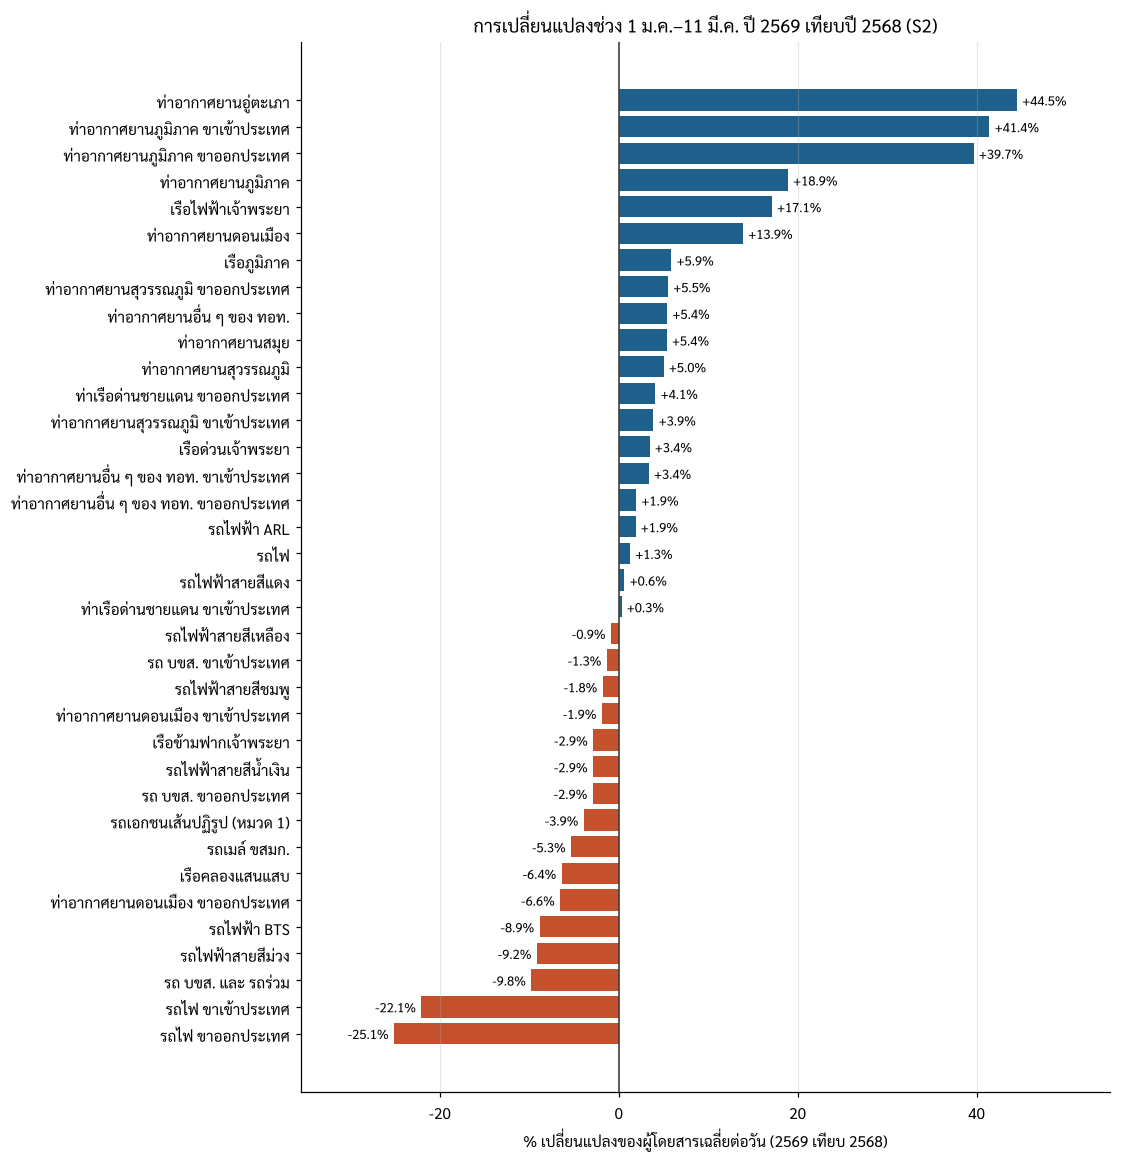

In [6]:
fig = q2_yoy.plot_yoy_bars(table, f" ({q2_yoy.MAIN_SCENARIO})")
plots.save_fig(fig, "q2_yoy_bars"); plt.show()

> ✍️ **ร่างการตีความ** เขียนจากผลที่รันจริง ทีมต้องอ่านทวนและปรับให้เป็นคำของตัวเองก่อนใส่รายงาน

เลือก diverging bar เพราะค่ามีทั้งบวกและลบ สีแยกทิศทางได้ทันที และเรียงลำดับให้เห็นอันดับในกราฟเดียว
- คำนวณได้ 36 บริการ เพิ่มขึ้น 20 บริการ ลดลง 16 บริการ
- เพิ่มมากที่สุดคือสนามบิน: อู่ตะเภา +44.5% (แต่ฐานเล็ก 201 → 291 คน/วัน), สนามบินภูมิภาคระหว่างประเทศ +40–41%, สนามบินภูมิภาคในประเทศ +18.9%, ดอนเมืองในประเทศ +13.9%
- ลดมากที่สุดคือรถไฟระหว่างประเทศ (−22% ถึง −25% จากฐานราว 360 คน/วัน) รองลงมาคือ รถ บขส. และรถร่วม −9.8%, สายสีม่วง −9.2%, BTS −8.9%
- ถ้าดูจำนวนจริง BTS ลดมากที่สุด (−69,419 คน/วัน) ตามด้วย ขสมก. (−28,645 คน/วัน)

### กราฟที่ 2: อันดับภายใต้วิธีจัดการ S1–S5 (heatmap)

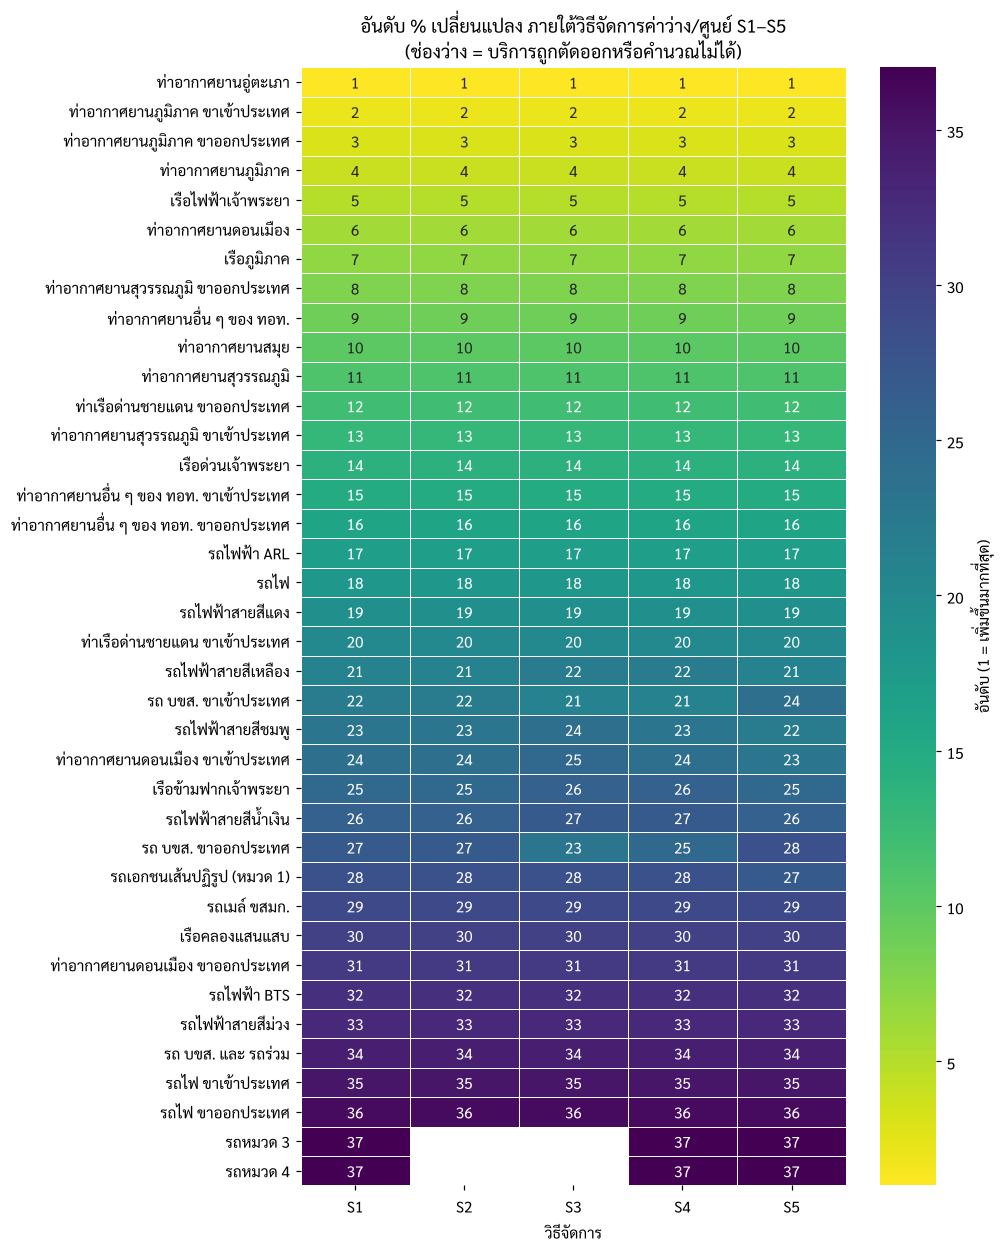

In [7]:
fig = q2_yoy.plot_rank_by_scenario(sensitivity)
plots.save_fig(fig, "q2_rank_by_scenario"); plt.show()

> ✍️ **ร่างการตีความ** เขียนจากผลที่รันจริง ทีมต้องอ่านทวนและปรับให้เป็นคำของตัวเองก่อนใส่รายงาน

เลือก heatmap เพราะต้องเทียบอันดับของทุกบริการพร้อมกันใน 5 วิธี ช่องว่างแสดงบริการที่ถูกตัดออกในวิธีนั้น
- **จุดที่เปลี่ยนข้อสรุป:** S1, S4, S5 ทำให้รถหมวด 3 และหมวด 4 ดูเหมือนลดลง −100% (อันดับสุดท้าย) เพราะนับศูนย์ช่วงหยุดรายงานเป็นศูนย์จริง ส่วน S2 และ S3 ตัดสองบริการนี้ออก
- บริการที่เหลือ 36 รายการมีอันดับแทบไม่เปลี่ยน (Spearman ≥ 0.997 เมื่อเทียบกับ S1 และย้ายอันดับตั้งแต่ 2 ขั้นได้ไม่เกิน 1 บริการ) มีเพียง รถ บขส. ระหว่างประเทศ ที่ค่าเปลี่ยน เพราะมีวันว่างไม่กี่วัน (เช่น ขาออก −1.8% ใน S3 แต่ −4.3% ใน S5)

## 5. Analysis & Findings
> ✍️ **ร่างการตีความ** เขียนจากผลที่รันจริง ทีมต้องอ่านทวนและปรับให้เป็นคำของตัวเองก่อนใส่รายงาน

**คำตอบ:** ช่วง 1 ม.ค.–11 มี.ค. 2569 เทียบกับช่วงเดียวกันของ 2568 (70 วัน และวันหยุดสุดสัปดาห์ 20 วันเท่ากัน)
1. **การเดินทางทางอากาศเพิ่มขึ้น** โดยเฉพาะสนามบินภูมิภาค ขณะที่**ระบบขนส่งในเมืองลดลง** (BTS, สายสีม่วง, สายสีน้ำเงิน, ขสมก., รถเอกชนเส้นปฏิรูป) ภาพรวมตามกลุ่ม: ภายในจังหวัด/กทม. −4.5%, ระหว่างจังหวัด −1.2%, ระหว่างประเทศ +3.0%
2. **ผลของวิธีจัดการข้อมูล:** การเติมหรือตัดค่าว่าง (NaN) แทบไม่เปลี่ยนอันดับ แต่**การตีความศูนย์ช่วงยาว**เปลี่ยนข้อสรุปมาก ถ้าถือว่าเป็นศูนย์จริง (S1/S4/S5) จะสรุปผิดว่ารถหมวด 3/4 หายไปทั้งหมด ทีมจึงใช้ S2 เป็นวิธีหลักและรายงานรถหมวด 3/4 ว่า “เทียบไม่ได้ เนื่องจากหยุดรายงานตั้งแต่ ต.ค. 2568”
3. S5 (แทน NaN ด้วย 0) ทำให้ค่าลดลงเกินจริงในบริการที่มีวันว่าง แสดงว่าไม่ควรใช้

**ข้อจำกัด**
- ช่วงเทียบเพียง 70 วัน และวันในสัปดาห์ของวันที่เดียวกันไม่ตรงกัน (1 ม.ค. 2568 เป็นวันพุธ แต่ 2569 เป็นวันพฤหัส) แต่จำนวนวันหยุดสุดสัปดาห์เท่ากัน
- % เปลี่ยนแปลงของบริการฐานเล็ก (อู่ตะเภา, รถไฟระหว่างประเทศ) ผันผวนง่าย ควรอ่านคู่กับ `abs_change`
- ผลรวมต่อกลุ่มรวมเฉพาะวันที่มีค่า (บขส. ระหว่างประเทศมีวันว่างเล็กน้อย)

## 6. บันทึก Prepared Dataset

In [8]:
table.to_csv(prep.PREPARED_DIR / q2_yoy.OUTPUT_FILE, index=False, encoding="utf-8-sig")
sensitivity.to_csv(prep.PREPARED_DIR / q2_yoy.SENSITIVITY_FILE, index=False, encoding="utf-8-sig")
print(q2_yoy.OUTPUT_FILE, table.shape, "·", q2_yoy.SENSITIVITY_FILE, sensitivity.shape)

q2_yoy_comparison.csv (38, 10) · q2_missing_sensitivity.csv (191, 11)
